In [1]:
import numpy as np
import pandas as pd
import torch
import torch.nn as nn
from datetime import datetime
from sklearn.preprocessing import StandardScaler
from torch.utils.data import Dataset, DataLoader

# Reproducibility
torch.manual_seed(42)
np.random.seed(42)

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print(f"Using device: {device}")

Using device: cpu


In [2]:
data_path = "/kaggle/input/datasets/amandapriyashantha/sri-lanka-tourists-arrival/sri_lanka_district_tourism_ml_dataset.csv"
df = pd.read_csv(data_path)

# 0. Keep RAW values (targets for the climate and inflation models, taken BEFORE scaling overwrites them)
df['temp_raw'] = df['average temperature within the month'].astype(np.float32)
df['rain_raw'] = df['average rainfall within the month'].astype(np.float32)
df['inflation_raw'] = df['inflation for the month of the year'].astype(np.float32)

# 1. Structural Shock Flags
df['is_border_closure'] = ((df['year'] == 2020) & (df['month'].between(4, 11))).astype(np.float32)
df['is_easter_attack'] = ((df['year'] == 2019) & (df['month'].between(5, 8))).astype(np.float32)
df['is_economic_crisis'] = ((df['year'] == 2022) & (df['month'].between(3, 10))).astype(np.float32)

# 2. Agro-Climatic Zone Prior (Wet Zone vs. Dry/Intermediate)
wet_zone_districts = {
    'Colombo', 'Gampaha', 'Kalutara', 'Kandy',
    'Nuwara Eliya', 'Galle', 'Matara', 'Ratnapura', 'Kegalle'
}
df['is_wet_zone'] = df['District'].isin(wet_zone_districts).astype(np.float32)
df['is_wet_raw'] = df['is_wet_zone'].copy()   # unscaled copy for the climate model

# 3. Cyclical Month Encoding
#    1st harmonic: used by the tourism model
#    2nd harmonic: added for the climate model (captures two monsoon peaks per year)
df['month_sin'] = np.sin(2 * np.pi * df['month'] / 12.0).astype(np.float32)
df['month_cos'] = np.cos(2 * np.pi * df['month'] / 12.0).astype(np.float32)
df['month_sin2'] = np.sin(4 * np.pi * df['month'] / 12.0).astype(np.float32)
df['month_cos2'] = np.cos(4 * np.pi * df['month'] / 12.0).astype(np.float32)

# 4. District Categorical Mapping & Baseline Volume Prior (from Pre-crisis 2010-2018)
all_districts = sorted(df['District'].unique().tolist())
district_to_idx = {d: i for i, d in enumerate(all_districts)}
idx_to_district = {i: d for d, i in district_to_idx.items()}
df['district_idx'] = df['District'].map(district_to_idx)

# Compute district historical volume share to inject capacity inductive bias
pre_crisis_totals = df[df['year'] <= 2018].groupby('District')['number of tourists arrived for the month'].sum()
district_weight_map = (pre_crisis_totals / pre_crisis_totals.sum()).to_dict()
df['district_base_weight'] = df['District'].map(district_weight_map).astype(np.float32)

# 5. Continuous Features & Normalization (tourism model)
continuous_cols = [
    'inflation for the month of the year',
    'average temperature within the month',
    'average rainfall within the month',
    'month_sin',
    'month_cos',
    'is_wet_zone',
    'district_base_weight'
]

scaler = StandardScaler()
df[continuous_cols] = scaler.fit_transform(df[continuous_cols])

# 6. Target Transformation: log1p
target_col = 'number of tourists arrived for the month'
df['target_log'] = np.log1p(df[target_col].values).astype(np.float32)

# 7. Recency-Scaled Sample Weights (Downweight pre-2015, zero lockdown months)
def compute_sample_weight(row):
    if row['is_border_closure'] == 1.0:
        return 0.0
    if row['year'] >= 2018:
        return 1.25  # High priority to modern patterns
    elif row['year'] >= 2014:
        return 1.0
    return 0.75

df['sample_weight'] = df.apply(compute_sample_weight, axis=1).astype(np.float32)

print(f"Features prepared. Continuous feature count: {len(continuous_cols)}")

Features prepared. Continuous feature count: 7


In [3]:
class TourismDataset(Dataset):
    def __init__(self, cat_district, cont_features, shock_flags, targets, weights):
        self.cat_district = torch.tensor(cat_district, dtype=torch.long)
        self.cont_features = torch.tensor(cont_features, dtype=torch.float32)
        self.shock_flags = torch.tensor(shock_flags, dtype=torch.float32)
        self.targets = torch.tensor(targets, dtype=torch.float32).unsqueeze(1)
        self.weights = torch.tensor(weights, dtype=torch.float32).unsqueeze(1)

    def __len__(self):
        return len(self.targets)

    def __getitem__(self, idx):
        return (
            self.cat_district[idx],
            self.cont_features[idx],
            self.shock_flags[idx],
            self.targets[idx],
            self.weights[idx]
        )

# Temporal split: Use 2010–2022 for training, 2023–2024 for validation
train_mask = df['year'] <= 2022
val_mask = df['year'] > 2022

shock_cols = ['is_border_closure', 'is_easter_attack', 'is_economic_crisis']

train_dataset = TourismDataset(
    df.loc[train_mask, 'district_idx'].values,
    df.loc[train_mask, continuous_cols].values,
    df.loc[train_mask, shock_cols].values,
    df.loc[train_mask, 'target_log'].values,
    df.loc[train_mask, 'sample_weight'].values
)

val_dataset = TourismDataset(
    df.loc[val_mask, 'district_idx'].values,
    df.loc[val_mask, continuous_cols].values,
    df.loc[val_mask, shock_cols].values,
    df.loc[val_mask, 'target_log'].values,
    df.loc[val_mask, 'sample_weight'].values
)

train_loader = DataLoader(train_dataset, batch_size=32, shuffle=True)
val_loader = DataLoader(val_dataset, batch_size=32, shuffle=False)

print(f"Training samples: {len(train_dataset)} | Validation samples: {len(val_dataset)}")

Training samples: 3900 | Validation samples: 600


In [4]:
class TourismDemandNet(nn.Module):
    def __init__(self, num_districts, emb_dim=8, num_cont=7, num_shocks=3):
        super(TourismDemandNet, self).__init__()
        self.district_embedding = nn.Embedding(num_districts, emb_dim)
        
        in_dim = emb_dim + num_cont + num_shocks
        self.mlp = nn.Sequential(
            nn.Linear(in_dim, 64),
            nn.SiLU(),  # Swish activation for smooth gradient flow
            nn.BatchNorm1d(64),
            nn.Dropout(0.10),
            nn.Linear(64, 32),
            nn.SiLU(),
            nn.BatchNorm1d(32),
            nn.Linear(32, 1)
        )

    def forward(self, district_idx, cont_x, shock_x):
        emb = self.district_embedding(district_idx)
        x = torch.cat([emb, cont_x, shock_x], dim=1)
        return self.mlp(x)

def weighted_huber_loss(preds, targets, weights, delta=0.5):
    """
    Smooth L1 / Huber Loss on log scale:
    Behaves like MSE for small errors, like MAE for large errors.
    Prevents outlier peak months from destabilizing gradients.
    """
    diff = torch.abs(preds - targets)
    huber = torch.where(diff < delta, 0.5 * (diff ** 2), delta * (diff - 0.5 * delta))
    weighted = weights * huber
    return weighted.sum() / torch.clamp(weights.sum(), min=1.0)

model = TourismDemandNet(num_districts=len(all_districts), num_cont=len(continuous_cols)).to(device)
optimizer = torch.optim.AdamW(model.parameters(), lr=0.006, weight_decay=1e-4)
criterion = weighted_huber_loss

In [5]:
epochs = 80
best_val_loss = float('inf')

for epoch in range(1, epochs + 1):
    model.train()
    train_loss = 0.0
    
    for dist, cont, shock, target, weight in train_loader:
        dist = dist.to(device)
        cont = cont.to(device)
        shock = shock.to(device)
        target = target.to(device)
        weight = weight.to(device)
        
        optimizer.zero_grad()
        preds = model(dist, cont, shock)
        loss = criterion(preds, target, weight)
        loss.backward()
        optimizer.step()
        
        train_loss += loss.item() * len(dist)
        
    train_loss /= len(train_dataset)
    
    # Validation evaluation
    model.eval()
    val_loss = 0.0
    with torch.no_grad():
        for dist, cont, shock, target, weight in val_loader:
            dist, cont, shock, target, weight = (
                dist.to(device), cont.to(device), shock.to(device), 
                target.to(device), weight.to(device)
            )
            preds = model(dist, cont, shock)
            loss = criterion(preds, target, weight)
            val_loss += loss.item() * len(dist)
            
    val_loss /= len(val_dataset)
    
    if val_loss < best_val_loss:
        best_val_loss = val_loss
        torch.save(model.state_dict(), "best_tourism_model.pth")
        
    if epoch % 10 == 0 or epoch == 1:
        print(f"Epoch {epoch:02d}/{epochs} | Train Loss (Weighted MSE): {train_loss:.4f} | Val Loss: {val_loss:.4f}")

# Load top-performing weights
model.load_state_dict(torch.load("best_tourism_model.pth"))
print("Model training complete. Best model weights restored.")

Epoch 01/80 | Train Loss (Weighted MSE): 1.4188 | Val Loss: 0.2191
Epoch 10/80 | Train Loss (Weighted MSE): 0.2676 | Val Loss: 0.0888
Epoch 20/80 | Train Loss (Weighted MSE): 0.2719 | Val Loss: 0.1614
Epoch 30/80 | Train Loss (Weighted MSE): 0.2519 | Val Loss: 0.0671
Epoch 40/80 | Train Loss (Weighted MSE): 0.2532 | Val Loss: 0.0731
Epoch 50/80 | Train Loss (Weighted MSE): 0.2591 | Val Loss: 0.0372
Epoch 60/80 | Train Loss (Weighted MSE): 0.2539 | Val Loss: 0.0570
Epoch 70/80 | Train Loss (Weighted MSE): 0.2494 | Val Loss: 0.0378
Epoch 80/80 | Train Loss (Weighted MSE): 0.2514 | Val Loss: 0.0570
Model training complete. Best model weights restored.


In [6]:
from sklearn.metrics import mean_absolute_error, r2_score

# ---------------------------------------------------------------
# CLIMATE MODEL: predicts (temperature, rainfall) from district + month
# ---------------------------------------------------------------
climate_feat_cols = ['month_sin', 'month_cos', 'month_sin2', 'month_cos2', 'is_wet_raw']

# Targets: temperature (°C) and log1p(rainfall mm), standardized using TRAIN rows only
clim_targets = np.stack([df['temp_raw'].values, np.log1p(df['rain_raw'].values)], axis=1).astype(np.float32)

clim_train_mask = (df['year'] <= 2022).values
clim_val_mask = (df['year'] > 2022).values

clim_scaler = StandardScaler().fit(clim_targets[clim_train_mask])
clim_targets_scaled = clim_scaler.transform(clim_targets).astype(np.float32)

class ClimateDataset(Dataset):
    def __init__(self, dist_idx, feats, targets):
        self.d = torch.tensor(dist_idx, dtype=torch.long)
        self.x = torch.tensor(feats, dtype=torch.float32)
        self.y = torch.tensor(targets, dtype=torch.float32)
    def __len__(self):
        return len(self.y)
    def __getitem__(self, i):
        return self.d[i], self.x[i], self.y[i]

clim_X = df[climate_feat_cols].values.astype(np.float32)
clim_D = df['district_idx'].values

clim_train_loader = DataLoader(
    ClimateDataset(clim_D[clim_train_mask], clim_X[clim_train_mask], clim_targets_scaled[clim_train_mask]),
    batch_size=64, shuffle=True)
clim_val_loader = DataLoader(
    ClimateDataset(clim_D[clim_val_mask], clim_X[clim_val_mask], clim_targets_scaled[clim_val_mask]),
    batch_size=64, shuffle=False)

class ClimateNet(nn.Module):
    def __init__(self, num_districts, emb_dim=8, num_feats=5):
        super().__init__()
        self.emb = nn.Embedding(num_districts, emb_dim)
        self.mlp = nn.Sequential(
            nn.Linear(emb_dim + num_feats, 64),
            nn.SiLU(),
            nn.Dropout(0.10),
            nn.Linear(64, 32),
            nn.SiLU(),
            nn.Linear(32, 2)       # [temperature, log1p(rainfall)]
        )
    def forward(self, d, x):
        return self.mlp(torch.cat([self.emb(d), x], dim=1))

climate_model = ClimateNet(len(all_districts), num_feats=len(climate_feat_cols)).to(device)
clim_opt = torch.optim.AdamW(climate_model.parameters(), lr=0.005, weight_decay=1e-4)
clim_loss_fn = nn.SmoothL1Loss()

best_clim_val = float('inf')
for epoch in range(1, 151):
    climate_model.train()
    for d, x, y in clim_train_loader:
        d, x, y = d.to(device), x.to(device), y.to(device)
        clim_opt.zero_grad()
        loss = clim_loss_fn(climate_model(d, x), y)
        loss.backward()
        clim_opt.step()

    climate_model.eval()
    v_loss, n = 0.0, 0
    with torch.no_grad():
        for d, x, y in clim_val_loader:
            d, x, y = d.to(device), x.to(device), y.to(device)
            v_loss += clim_loss_fn(climate_model(d, x), y).item() * len(d)
            n += len(d)
    v_loss /= n

    if v_loss < best_clim_val:
        best_clim_val = v_loss
        torch.save(climate_model.state_dict(), "best_climate_model.pth")
    if epoch % 25 == 0 or epoch == 1:
        print(f"Climate Epoch {epoch:03d}/150 | Val Loss: {v_loss:.4f}")

climate_model.load_state_dict(torch.load("best_climate_model.pth"))
climate_model.eval()

# ---------------------------------------------------------------
# Helper: predict climate for any district + month
# ---------------------------------------------------------------
def predict_climate(district, month):
    """Returns (temperature_C, rainfall_mm) predicted by the climate model."""
    feats = np.array([[
        np.sin(2 * np.pi * month / 12.0),
        np.cos(2 * np.pi * month / 12.0),
        np.sin(4 * np.pi * month / 12.0),
        np.cos(4 * np.pi * month / 12.0),
        1.0 if district in wet_zone_districts else 0.0
    ]], dtype=np.float32)
    with torch.no_grad():
        out = climate_model(
            torch.tensor([district_to_idx[district]], dtype=torch.long).to(device),
            torch.tensor(feats).to(device)
        ).cpu().numpy()
    temp, rain_log = clim_scaler.inverse_transform(out)[0]
    return float(temp), float(max(0.0, np.expm1(rain_log)))

# ---------------------------------------------------------------
# Validation (2023-2024) in original units
# ---------------------------------------------------------------
with torch.no_grad():
    d_all = torch.tensor(clim_D[clim_val_mask], dtype=torch.long).to(device)
    x_all = torch.tensor(clim_X[clim_val_mask]).to(device)
    pred_scaled = climate_model(d_all, x_all).cpu().numpy()

pred_inv = clim_scaler.inverse_transform(pred_scaled)
true_inv = clim_scaler.inverse_transform(clim_targets_scaled[clim_val_mask])

pred_temp, true_temp = pred_inv[:, 0], true_inv[:, 0]
pred_rain, true_rain = np.expm1(pred_inv[:, 1]), np.expm1(true_inv[:, 1])

print("=" * 55)
print("CLIMATE MODEL VALIDATION (2023 - 2024)")
print("=" * 55)
print(f"Temperature  | MAE: {mean_absolute_error(true_temp, pred_temp):.2f} °C | R²: {r2_score(true_temp, pred_temp):.3f}")
print(f"Rainfall     | MAE: {mean_absolute_error(true_rain, pred_rain):.1f} mm | R²: {r2_score(true_rain, pred_rain):.3f}")
print("=" * 55)

# Quick sanity check
for d, m in [("Galle", 5), ("Galle", 1), ("Trincomalee", 11), ("Trincomalee", 7)]:
    t, r = predict_climate(d, m)
    print(f"{d:<12} month {m:>2}: {t:.1f}°C, {r:.0f} mm")

Climate Epoch 001/150 | Val Loss: 0.0426
Climate Epoch 025/150 | Val Loss: 0.0005
Climate Epoch 050/150 | Val Loss: 0.0007
Climate Epoch 075/150 | Val Loss: 0.0004
Climate Epoch 100/150 | Val Loss: 0.0006
Climate Epoch 125/150 | Val Loss: 0.0008
Climate Epoch 150/150 | Val Loss: 0.0007
CLIMATE MODEL VALIDATION (2023 - 2024)
Temperature  | MAE: 0.05 °C | R²: 0.999
Rainfall     | MAE: 3.3 mm | R²: 0.998
Galle        month  5: 28.3°C, 367 mm
Galle        month  1: 26.6°C, 89 mm
Trincomalee  month 11: 28.2°C, 326 mm
Trincomalee  month  7: 29.1°C, 42 mm


In [7]:
from sklearn.linear_model import Ridge
from sklearn.metrics import mean_absolute_error

# ---------------------------------------------------------------
# NATIONAL MONTHLY INFLATION SERIES (one value per year-month)
# ---------------------------------------------------------------
infl = (df.groupby(['year', 'month'])['inflation_raw'].mean()
          .reset_index().sort_values(['year', 'month']).reset_index(drop=True))
infl_series = infl['inflation_raw'].values.astype(np.float64)
infl_dates = list(zip(infl['year'].astype(int), infl['month'].astype(int)))

N_LAGS = 3
PERSISTENCE = 0.90   # how fast the AR influence fades per month (lower = reverts to target faster)

def make_lag_matrix(series, n_lags=N_LAGS):
    X = np.array([series[i - n_lags:i][::-1] for i in range(n_lags, len(series))])
    y = series[n_lags:]
    return X, y

def fit_ar(series, n_lags=N_LAGS, alpha=1.0):
    X, y = make_lag_matrix(series, n_lags)
    return Ridge(alpha=alpha).fit(X, y)

def recursive_forecast(ar_model, history, steps, target, damped=True, n_lags=N_LAGS):
    """
    Roll the AR model forward `steps` months.
    damped=True : AR weight fades as PERSISTENCE**k, so long horizons settle at `target`
    damped=False: plain AR (reverts to its own, crisis-inflated mean)
    """
    hist = list(history[-n_lags:])
    out = []
    for k in range(1, steps + 1):
        x = np.array(hist[-n_lags:][::-1]).reshape(1, -1)
        ar_pred = float(ar_model.predict(x)[0])
        if damped:
            w = PERSISTENCE ** k
            nxt = w * ar_pred + (1 - w) * target
        else:
            nxt = ar_pred
        nxt = float(np.clip(nxt, -5.0, 100.0))
        out.append(nxt)
        hist.append(nxt)
    return np.array(out)

# ---------------------------------------------------------------
# VALIDATION: train through 2022, forecast 2023-2024 recursively
# (the target uses TRAIN data only, so there is no leakage)
# ---------------------------------------------------------------
split_idx = max(i for i, (y, m) in enumerate(infl_dates) if y <= 2022)
train_series = infl_series[:split_idx + 1]
actual = infl_series[split_idx + 1:]
val_target = float(np.median(train_series))

ar_val = fit_ar(train_series)
fc_plain = recursive_forecast(ar_val, train_series, len(actual), val_target, damped=False)
fc_damped = recursive_forecast(ar_val, train_series, len(actual), val_target, damped=True)

print("=" * 58)
print("INFLATION MODEL VALIDATION (recursive forecast 2023-2024)")
print("=" * 58)
print(f"Plain AR MAE          : {mean_absolute_error(actual, fc_plain):.2f} pp")
print(f"Damped AR MAE         : {mean_absolute_error(actual, fc_damped):.2f} pp")
print(f"Mean-baseline MAE     : {mean_absolute_error(actual, np.full(len(actual), train_series.mean())):.2f} pp")
print(f"Median-baseline MAE   : {mean_absolute_error(actual, np.full(len(actual), val_target)):.2f} pp")
print(f"Naive (last value) MAE: {mean_absolute_error(actual, np.full(len(actual), train_series[-1])):.2f} pp")
print("=" * 58)

# ---------------------------------------------------------------
# PRODUCTION: refit on all data, anchor to the median of ALL data
# ---------------------------------------------------------------
INFLATION_TARGET = float(np.median(infl_series))   # ~5.45% on your data; set manually to override
ar_full = fit_ar(infl_series)
last_year, last_month = infl_dates[-1]
MAX_HORIZON = 120
future_path = recursive_forecast(ar_full, infl_series, MAX_HORIZON, INFLATION_TARGET, damped=True)
known_lookup = {d: v for d, v in zip(infl_dates, infl_series)}

def predict_inflation(year, month):
    """Returns inflation (%) for a year/month: actual if known, damped forecast otherwise."""
    if (year, month) in known_lookup:
        return float(known_lookup[(year, month)])
    steps = (year - last_year) * 12 + (month - last_month)
    if steps <= 0:
        return float(infl_series[-1])
    return float(future_path[min(steps, MAX_HORIZON) - 1])

print(f"Long-run target used     : {INFLATION_TARGET:.2f}%")
print(f"Last known data point    : {last_year}-{last_month:02d} -> {infl_series[-1]:.2f}%")
print("\nForecast path:")
for y, m in [(2025, 6), (2026, 1), (2026, 6), (2026, 11), (2027, 6), (2028, 6)]:
    print(f"  {y}-{m:02d}: {predict_inflation(y, m):.2f}%")

# ---------------------------------------------------------------
# FORECAST FROM A USER-SUPPLIED CURRENT RATE
# ---------------------------------------------------------------
def predict_inflation_from_current(current_rates, as_of_year, as_of_month, target_year, target_month):
    """
    current_rates : list of the most recent actual rates, oldest -> newest
                    (1 to 3 values; the last one is the rate for as_of year/month)
    Seeds the AR model with real recent values, then rolls forward to the target month,
    fading toward INFLATION_TARGET as the horizon grows.
    """
    steps = (target_year - as_of_year) * 12 + (target_month - as_of_month)
    if steps <= 0:
        return float(current_rates[-1])

    # Pad to N_LAGS using the oldest supplied value, so a single input still works
    seed = list(current_rates)[-N_LAGS:]
    while len(seed) < N_LAGS:
        seed.insert(0, seed[0])

    path = recursive_forecast(ar_full, seed, steps, INFLATION_TARGET, damped=True)
    return float(path[-1])

# Quick test: if current inflation is 2.0% as of Oct 2026
for y, m in [(2026, 12), (2027, 6), (2028, 6)]:
    print(f"From 2.0% in 2026-10 -> {y}-{m:02d}: {predict_inflation_from_current([2.0], 2026, 10, y, m):.2f}%")

INFLATION MODEL VALIDATION (recursive forecast 2023-2024)
Plain AR MAE          : 5.35 pp
Damped AR MAE         : 8.74 pp
Mean-baseline MAE     : 12.10 pp
Median-baseline MAE   : 10.86 pp
Naive (last value) MAE: 46.34 pp
Long-run target used     : 5.45%
Last known data point    : 2024-12 -> -1.70%

Forecast path:
  2025-06: 6.52%
  2026-01: 5.50%
  2026-06: 5.47%
  2026-11: 5.46%
  2027-06: 5.46%
  2028-06: 5.45%
From 2.0% in 2026-10 -> 2026-12: 3.62%
From 2.0% in 2026-10 -> 2027-06: 5.61%
From 2.0% in 2026-10 -> 2028-06: 5.47%


             VALIDATION METRICS SUMMARY (2023 - 2024)
R² Score (Coefficient of Determination) : 0.9129
Mean Absolute Error (MAE)              : 1,278.5 tourists
Root Mean Squared Error (RMSE)         : 2,677.3 tourists
Mean Absolute Percentage Error (MAPE)  : 21.80%


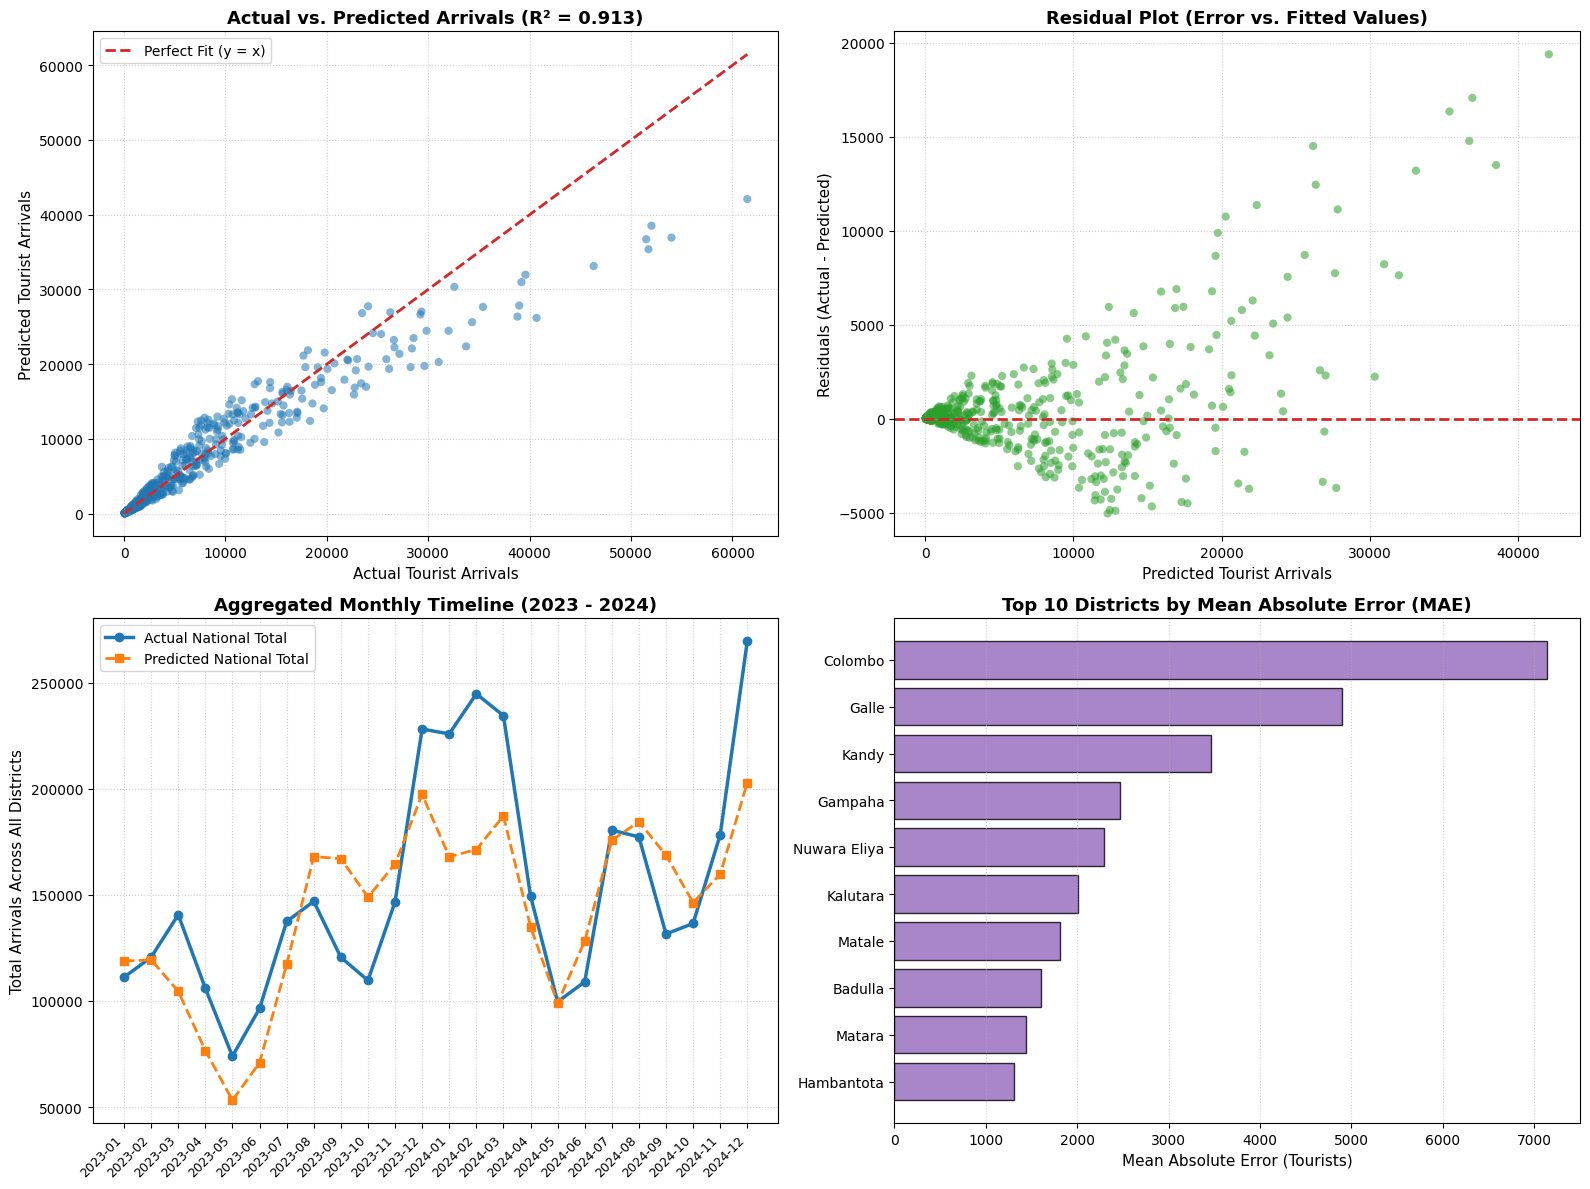

In [8]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import torch
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

# -------------------------------------------------------------------------
# 1. Run Evaluation on the Unseen Validation Set (2023–2024)
# -------------------------------------------------------------------------
model.eval()

all_dist_idx = []
all_actual_log = []
all_pred_log = []

with torch.no_grad():
    for dist, cont, shock, target, weight in val_loader:
        dist = dist.to(device)
        cont = cont.to(device)
        shock = shock.to(device)

        preds = model(dist, cont, shock)

        all_dist_idx.extend(dist.cpu().numpy().flatten())
        all_actual_log.extend(target.numpy().flatten())
        all_pred_log.extend(preds.cpu().numpy().flatten())

all_dist_idx = np.array(all_dist_idx)
all_actual_log = np.array(all_actual_log)
all_pred_log = np.array(all_pred_log)

# Inverse transform from log(1 + y) back to raw count of tourist arrivals
y_true_raw = np.expm1(all_actual_log)
y_pred_raw = np.maximum(0, np.expm1(all_pred_log))
residuals_raw = y_true_raw - y_pred_raw

# -------------------------------------------------------------------------
# 2. Compute Quantitative Regression Metrics
# -------------------------------------------------------------------------
r2_val = r2_score(y_true_raw, y_pred_raw)
mae_val = mean_absolute_error(y_true_raw, y_pred_raw)
rmse_val = np.sqrt(mean_squared_error(y_true_raw, y_pred_raw))
mape_val = np.mean(np.abs(residuals_raw) / np.maximum(y_true_raw, 1.0)) * 100

print("=" * 60)
print("             VALIDATION METRICS SUMMARY (2023 - 2024)")
print("=" * 60)
print(f"R² Score (Coefficient of Determination) : {r2_val:.4f}")
print(f"Mean Absolute Error (MAE)              : {mae_val:,.1f} tourists")
print(f"Root Mean Squared Error (RMSE)         : {rmse_val:,.1f} tourists")
print(f"Mean Absolute Percentage Error (MAPE)  : {mape_val:.2f}%")
print("=" * 60)

# -------------------------------------------------------------------------
# 3. Diagnostic Plots (2x2 Dashboard)
# -------------------------------------------------------------------------
fig, axes = plt.subplots(2, 2, figsize=(16, 12))
plt.subplots_adjust(hspace=0.28, wspace=0.22)

# --- Plot 1: Actual vs. Predicted (Log-Log / Raw Scatter) ---
max_val = max(y_true_raw.max(), y_pred_raw.max())
axes[0, 0].scatter(y_true_raw, y_pred_raw, color="#1f77b4", alpha=0.55, edgecolor="none", s=35)
axes[0, 0].plot([0, max_val], [0, max_val], color="#d62728", linestyle="--", linewidth=2, label="Perfect Fit (y = x)")
axes[0, 0].set_title(f"Actual vs. Predicted Arrivals (R² = {r2_val:.3f})", fontsize=13, fontweight="bold")
axes[0, 0].set_xlabel("Actual Tourist Arrivals", fontsize=11)
axes[0, 0].set_ylabel("Predicted Tourist Arrivals", fontsize=11)
axes[0, 0].grid(True, linestyle=":", alpha=0.6)
axes[0, 0].legend(loc="upper left")

# --- Plot 2: Residuals vs. Fitted Values ---
axes[0, 1].scatter(y_pred_raw, residuals_raw, color="#2ca02c", alpha=0.55, edgecolor="none", s=35)
axes[0, 1].axhline(0, color="#d62728", linestyle="--", linewidth=2)
axes[0, 1].set_title("Residual Plot (Error vs. Fitted Values)", fontsize=13, fontweight="bold")
axes[0, 1].set_xlabel("Predicted Tourist Arrivals", fontsize=11)
axes[0, 1].set_ylabel("Residuals (Actual - Predicted)", fontsize=11)
axes[0, 1].grid(True, linestyle=":", alpha=0.6)

# --- Plot 3: Aggregated Monthly Time Series (Actual vs. Predicted) ---
# Attach validation predictions to evaluate aggregated monthly trajectory
val_df = df.loc[val_mask].copy().reset_index(drop=True)
val_df["y_true"] = y_true_raw
val_df["y_pred"] = y_pred_raw

monthly_trajectory = val_df.groupby(["year", "month"])[["y_true", "y_pred"]].sum().reset_index()
monthly_trajectory["date_str"] = monthly_trajectory.apply(lambda r: f"{int(r.year)}-{int(r.month):02d}", axis=1)

x_ticks = np.arange(len(monthly_trajectory))
axes[1, 0].plot(x_ticks, monthly_trajectory["y_true"], marker="o", color="#1f77b4", linewidth=2.5, label="Actual National Total")
axes[1, 0].plot(x_ticks, monthly_trajectory["y_pred"], marker="s", color="#ff7f0e", linestyle="--", linewidth=2, label="Predicted National Total")
axes[1, 0].set_xticks(x_ticks)
axes[1, 0].set_xticklabels(monthly_trajectory["date_str"], rotation=45, ha="right", fontsize=9)
axes[1, 0].set_title("Aggregated Monthly Timeline (2023 - 2024)", fontsize=13, fontweight="bold")
axes[1, 0].set_ylabel("Total Arrivals Across All Districts", fontsize=11)
axes[1, 0].grid(True, linestyle=":", alpha=0.6)
axes[1, 0].legend(loc="upper left")

# --- Plot 4: Mean Absolute Error by District (Top 10 Districts) ---
val_df["abs_err"] = np.abs(residuals_raw)
district_mae = val_df.groupby("District")["abs_err"].mean().sort_values(ascending=False).head(10)

bars = axes[1, 1].barh(district_mae.index[::-1], district_mae.values[::-1], color="#9467bd", edgecolor="black", alpha=0.8)
axes[1, 1].set_title("Top 10 Districts by Mean Absolute Error (MAE)", fontsize=13, fontweight="bold")
axes[1, 1].set_xlabel("Mean Absolute Error (Tourists)", fontsize=11)
axes[1, 1].grid(axis="x", linestyle=":", alpha=0.6)

plt.tight_layout()
plt.show()

In [9]:
# Quick Sanity Check: Test seasonal inversion between Galle (Southwest) and Trincomalee (East)
test_months = [1, 7]  # Jan (Southwest peak) vs July (East peak)
sample_districts = ["Galle", "Trincomalee"]

print(f"{'District':<15} {'Month':<8} {'Predicted Volume':<18}")
print("-" * 42)

for d in sample_districts:
    is_wz = 1.0 if d in wet_zone_districts else 0.0
    weight = district_weight_map.get(d, 0.01)
    
    for m in test_months:
        m_sin = np.sin(2 * np.pi * m / 12.0)
        m_cos = np.cos(2 * np.pi * m / 12.0)
        # Hold temp at 28°C, rain at 100mm, inflation at 5.0%
        feat = scaler.transform([[5.0, 28.0, 100.0, m_sin, m_cos, is_wz, weight]])
        
        with torch.no_grad():
            pred_log = model(
                torch.tensor([district_to_idx[d]]).to(device),
                torch.tensor(feat, dtype=torch.float32).to(device),
                torch.tensor([[0.0, 0.0, 0.0]]).to(device)
            ).item()
        pred = int(round(np.expm1(pred_log)))
        m_name = "January" if m == 1 else "July"
        print(f"{d:<15} {m_name:<8} {pred:<18,}")

District        Month    Predicted Volume  
------------------------------------------
Galle           January  31,079            
Galle           July     20,107            
Trincomalee     January  2,601             
Trincomalee     July     3,664             


/usr/local/lib/python3.13/dist-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but StandardScaler was fitted with feature names
  warnings.warn(
/usr/local/lib/python3.13/dist-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but StandardScaler was fitted with feature names
  warnings.warn(
/usr/local/lib/python3.13/dist-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but StandardScaler was fitted with feature names
  warnings.warn(
/usr/local/lib/python3.13/dist-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but StandardScaler was fitted with feature names
  warnings.warn(


In [13]:
import math
import itertools
import numpy as np
import pandas as pd
import torch

# ---------------------------------------------------------------
# BACKGROUND: "typical" normal situations the explanation is measured against
# (non-crisis months, usable training rows only)
# ---------------------------------------------------------------
_normal_mask = ((df[shock_cols] == 0).all(axis=1)) & (df['sample_weight'] > 0)
_bg_df = df.loc[_normal_mask].sample(n=min(300, int(_normal_mask.sum())), random_state=42)

BG_DIST = _bg_df['district_idx'].values.astype(np.int64)
BG_CONT = _bg_df[continuous_cols].values.astype(np.float32)      # already scaled
BG_RAW = {                                                        # averages in real units, for wording
    'temperature': float(_bg_df['temp_raw'].mean()),
    'rainfall':    float(_bg_df['rain_raw'].mean()),
    'inflation':   float(_bg_df['inflation_raw'].mean()),
}
BG_AVG_SHARE = float(np.mean(list(district_weight_map.values())))

# ---------------------------------------------------------------
# FEATURE GROUPS: related inputs are explained together as one human-readable factor
# ---------------------------------------------------------------
_ci = {c: i for i, c in enumerate(continuous_cols)}
XAI_GROUPS = {
    'district':    [_ci['is_wet_zone'], _ci['district_base_weight']],   # + district embedding
    'season':      [_ci['month_sin'], _ci['month_cos']],
    'temperature': [_ci['average temperature within the month']],
    'rainfall':    [_ci['average rainfall within the month']],
    'inflation':   [_ci['inflation for the month of the year']],
}
GROUP_NAMES = list(XAI_GROUPS)

@torch.no_grad()
def _predict_log(dist_idx, cont):
    """Tourism model output (log1p scale) for a batch. Shock flags are 0 (normal future travel)."""
    model.eval()
    d = torch.tensor(dist_idx, dtype=torch.long, device=device)
    c = torch.tensor(cont, dtype=torch.float32, device=device)
    s = torch.zeros((len(d), 3), dtype=torch.float32, device=device)
    return model(d, c, s).squeeze(1).cpu().numpy()

def shapley_for_row(x_dist, x_cont):
    """
    Exact Shapley values (log space) for one input row over the 5 factor groups.
    A factor that is 'absent' takes its value from the background rows (interventional SHAP).
    Returns: (phi dict, baseline_log, prediction_log). Sum(phi) + baseline == prediction exactly.
    """
    n = len(GROUP_NAMES)
    value = {}
    for r in range(n + 1):
        for subset in itertools.combinations(range(n), r):
            d = BG_DIST.copy()
            c = BG_CONT.copy()
            for gi in subset:
                g = GROUP_NAMES[gi]
                c[:, XAI_GROUPS[g]] = x_cont[XAI_GROUPS[g]]
                if g == 'district':
                    d[:] = x_dist
            value[subset] = float(_predict_log(d, c).mean())

    phi = {}
    for i, g in enumerate(GROUP_NAMES):
        others = [j for j in range(n) if j != i]
        total = 0.0
        for r in range(n):
            w = math.factorial(r) * math.factorial(n - r - 1) / math.factorial(n)
            for S in itertools.combinations(others, r):
                total += w * (value[tuple(sorted(S + (i,)))] - value[S])
        phi[g] = total
    return phi, value[()], value[tuple(range(n))]

def explain_prediction(district, target_month, temp, rain, infl):
    """Builds the model input exactly like inference does, then explains the prediction."""
    is_wz = 1.0 if district in wet_zone_districts else 0.0
    dist_share = float(district_weight_map.get(district, 0.01))
    cont_df = pd.DataFrame([{
        'inflation for the month of the year': infl,
        'average temperature within the month': temp,
        'average rainfall within the month': rain,
        'month_sin': float(np.sin(2 * np.pi * target_month / 12.0)),
        'month_cos': float(np.cos(2 * np.pi * target_month / 12.0)),
        'is_wet_zone': is_wz,
        'district_base_weight': dist_share,
    }])[continuous_cols]
    x_cont = scaler.transform(cont_df)[0].astype(np.float32)

    phi, base_log, fx_log = shapley_for_row(district_to_idx[district], x_cont)
    assert abs(sum(phi.values()) + base_log - fx_log) < 1e-3, "Shapley values do not add up!"

    return {
        'district': district, 'month': target_month,
        'temp': temp, 'rain': rain, 'infl': infl,
        'zone': 'Wet Zone' if is_wz == 1.0 else 'Dry/Intermediate Zone',
        'dist_share': dist_share,
        'phi': phi, 'base_log': base_log, 'fx_log': fx_log,
        'pred': max(0, int(round(np.expm1(fx_log)))),
        'baseline': max(0, int(round(np.expm1(base_log)))),
    }

print(f"Explainer ready. Background rows: {len(BG_DIST)} | "
      f"typical temp {BG_RAW['temperature']:.1f}°C, rain {BG_RAW['rainfall']:.0f} mm, "
      f"inflation {BG_RAW['inflation']:.1f}%")

Explainer ready. Background rows: 300 | typical temp 27.5°C, rain 158 mm, inflation 6.7%


In [16]:
import calendar
import matplotlib.pyplot as plt

FACTOR_LABELS = {
    'district':    'Destination (district)',
    'season':      'Time of year',
    'temperature': 'Temperature',
    'rainfall':    'Rainfall',
    'inflation':   'Inflation',
}

def _pct(phi_log):
    return (math.exp(phi_log) - 1.0) * 100.0

def _strength(p):
    a = abs(p)
    if a < 3:  return "negligible"
    if a < 10: return "small"
    if a < 25: return "moderate"
    return "strong"

def _describe_factor(g, e, p):
    """One plain-English sentence about the factor's value (before its effect)."""
    d = e['district']
    month_name = calendar.month_name[e['month']]
    if g == 'district':
        share, avg = e['dist_share'] * 100, BG_AVG_SHARE * 100
        rel = "larger" if share > avg else "smaller"
        return (f"{d} ({e['zone']}) historically receives about {share:.1f}% of national arrivals, "
                f"a {rel} share than the average district ({avg:.1f}%).")
    if g == 'season':
        tone = "busier" if p > 0 else "quieter"
        return f"{month_name} is a {tone} time of year for tourism here, based on past seasonal patterns."
    if g == 'temperature':
        diff = e['temp'] - BG_RAW['temperature']
        if abs(diff) < 0.3:
            return f"The expected temperature ({e['temp']:.1f}°C) is close to the average ({BG_RAW['temperature']:.1f}°C)."
        word = "warmer" if diff > 0 else "cooler"
        return f"The expected temperature ({e['temp']:.1f}°C) is {word} than the average ({BG_RAW['temperature']:.1f}°C)."
    if g == 'rainfall':
        diff = e['rain'] - BG_RAW['rainfall']
        if abs(diff) < 10:
            return f"The expected rainfall ({e['rain']:.0f} mm) is close to the average ({BG_RAW['rainfall']:.0f} mm)."
        word = "wetter" if diff > 0 else "drier"
        return f"The expected rainfall ({e['rain']:.0f} mm) is {word} than the average ({BG_RAW['rainfall']:.0f} mm)."
    if g == 'inflation':
        diff = e['infl'] - BG_RAW['inflation']
        if abs(diff) < 0.5:
            return f"The expected inflation ({e['infl']:.1f}%) is close to the historical average ({BG_RAW['inflation']:.1f}%)."
        word = "higher" if diff > 0 else "lower"
        return f"The expected inflation ({e['infl']:.1f}%) is {word} than the historical average ({BG_RAW['inflation']:.1f}%)."

def explain_in_words(e, parsed_date, current_infl=None, months_ahead=None):
    pcts = {g: _pct(v) for g, v in e['phi'].items()}
    order = sorted(pcts, key=lambda g: abs(pcts[g]), reverse=True)
    overall = (e['pred'] / max(e['baseline'], 1) - 1) * 100
    month_year = parsed_date.strftime('%B %Y')

    print("\n" + "=" * 70)
    print("WHY DID THE MODEL MAKE THIS PREDICTION?")
    print("=" * 70)
    print(f"The model forecasts about {e['pred']:,} tourists for {e['district']} in {month_year}.")
    print(f"A typical district-month in the historical data sees roughly {e['baseline']:,} tourists, "
          f"so this forecast is about {abs(overall):.0f}% {'above' if overall > 0 else 'below'} that average.")

    main = [g for g in order if abs(pcts[g]) >= 3][:2]
    if main:
        parts = [f"{FACTOR_LABELS[g].lower()} ({'raising' if pcts[g] > 0 else 'lowering'} it)" for g in main]
        print("The biggest influences were " + " and ".join(parts) + ".")
    else:
        print("No single factor strongly moved the forecast away from the average.")

    print("\nFactor by factor (most influential first):")
    for rank, g in enumerate(order, 1):
        p = pcts[g]
        arrow = "▲" if p > 0 else "▼"
        s = _strength(p)
        if s == "negligible":
            effect = "This had almost no influence on the forecast."
        else:
            effect = (f"This {'pushed the forecast up' if p > 0 else 'pulled the forecast down'} "
                      f"by about {abs(p):.0f}% ({s} effect).")
        print(f"\n {rank}. {FACTOR_LABELS[g]}  {arrow} {p:+.0f}%")
        print(f"    {_describe_factor(g, e, p)}")
        print(f"    {effect}")

    print("\nThings to keep in mind:")
    print(" • These are patterns the model learned from past data. They show association, not proven cause and effect.")
    print(" • Temperature and rainfall are the usual seasonal values for this district and month, not a weather forecast.")
    if months_ahead is not None and current_infl is not None:
        note = (f" • Inflation was projected from today's rate of {current_infl:.1f}% over {months_ahead} month(s).")
        if months_ahead > 12:
            note += " Beyond about a year this projection is uncertain, so treat the forecast with extra caution."
        print(note)
    print(" • Percentages are approximate and combine multiplicatively, so they will not add up exactly to the total change.")
    print("=" * 70)

def plot_explanation(e):
    pcts = {g: _pct(v) for g, v in e['phi'].items()}
    order = sorted(pcts, key=lambda g: abs(pcts[g]))
    labels = [FACTOR_LABELS[g] for g in order]
    vals = [pcts[g] for g in order]
    colors = ['#2ca02c' if v > 0 else '#d62728' for v in vals]

    fig, ax = plt.subplots(figsize=(9, 4.2))
    bars = ax.barh(labels, vals, color=colors, edgecolor='black', alpha=0.85)
    ax.axvline(0, color='black', linewidth=1)
    for b, v in zip(bars, vals):
        ax.text(v + (1 if v >= 0 else -1), b.get_y() + b.get_height() / 2, f"{v:+.0f}%",
                va='center', ha='left' if v >= 0 else 'right', fontsize=10, fontweight='bold')
    ax.set_title(f"What drove the forecast for {e['district']} ({calendar.month_name[e['month']]})\n"
                 f"Green = raises arrivals, Red = lowers arrivals (vs. a typical district-month)",
                 fontsize=11, fontweight='bold')
    ax.set_xlabel("Effect on expected tourist arrivals (%)")
    ax.grid(axis='x', linestyle=':', alpha=0.6)
    lim = max(abs(v) for v in vals) * 1.35 + 2
    ax.set_xlim(-lim, lim)
    plt.tight_layout()
    plt.show()

--- SRI LANKA TOURIST ARRIVAL PREDICTOR ---


Enter future travel date (YYYY-MM or YYYY-MM-DD), must be after 2026-10-12:  2026-12-16



Available Districts:
Ampara, Anuradhapura, Badulla, Batticaloa, Colombo, Galle, Gampaha, Hambantota, Jaffna, Kalutara, Kandy, Kegalle, Kilinochchi, Kurunegala, Mannar, Matale, Matara, Monaragala, Mullaitivu, Nuwara Eliya, Polonnaruwa, Puttalam, Ratnapura, Trincomalee, Vavuniya



Enter District name:  Galle
Enter CURRENT inflation rate (%) as of October 2026:  8



PREDICTED ARRIVAL REPORT
Destination:   Galle (Wet Zone)
Period:        December 2026  (2 months ahead)
Temperature:   26.6°C  (predicted)
Rainfall:      143.9 mm  (predicted)
Inflation:     7.3%  (predicted from current 8.0%)
Capacity Pr:   16.04% national share
Forecast:      ~22,149 tourists

WHY DID THE MODEL MAKE THIS PREDICTION?
The model forecasts about 22,149 tourists for Galle in December 2026.
A typical district-month in the historical data sees roughly 1,646 tourists, so this forecast is about 1246% above that average.
The biggest influences were destination (district) (raising it) and inflation (lowering it).

Factor by factor (most influential first):

 1. Destination (district)  ▲ +1259%
    Galle (Wet Zone) historically receives about 16.0% of national arrivals, a larger share than the average district (4.0%).
    This pushed the forecast up by about 1259% (strong effect).

 2. Inflation  ▼ -18%
    The expected inflation (7.3%) is higher than the historical average (6.

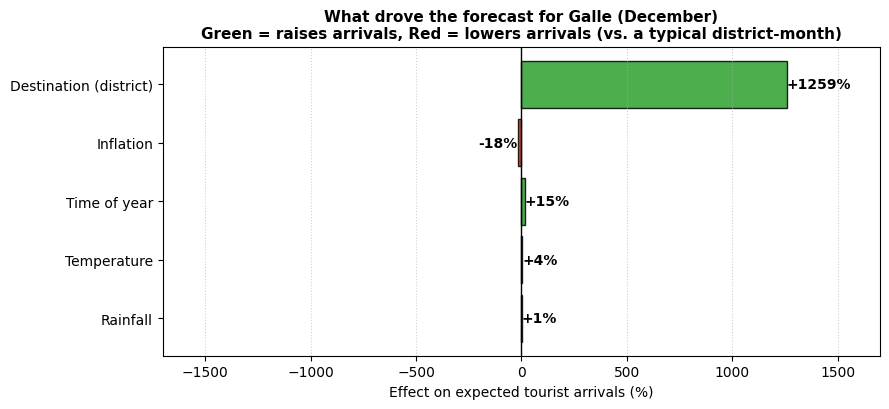

In [17]:
def run_manual_inference():
    model.eval()
    climate_model.eval()
    print("--- SRI LANKA TOURIST ARRIVAL PREDICTOR ---")

    # 1. Travel Date Input & Validation
    today = datetime.now().date()
    while True:
        date_str = input(f"Enter future travel date (YYYY-MM or YYYY-MM-DD), must be after {today}: ").strip()
        try:
            if len(date_str) == 7:
                parsed_date = datetime.strptime(date_str, "%Y-%m").date()
            else:
                parsed_date = datetime.strptime(date_str, "%Y-%m-%d").date()
            if parsed_date <= today:
                print(f"Error: The date must be in the future (after {today}). Please try again.")
                continue
            break
        except ValueError:
            print("Invalid date format. Use YYYY-MM (e.g., 2026-12) or YYYY-MM-DD.")

    target_year = parsed_date.year
    target_month = parsed_date.month

    # 2. District Selection
    print("\nAvailable Districts:\n" + ", ".join(all_districts))
    while True:
        district_input = input("\nEnter District name: ").strip().title()
        if district_input in district_to_idx:
            break
        print(f"'{district_input}' not recognized. Please choose from the available list.")

    # 3. Current inflation (actual, entered by the user)
    while True:
        try:
            current_infl = float(input(f"Enter CURRENT inflation rate (%) as of {today.strftime('%B %Y')}: "))
            break
        except ValueError:
            print("Please provide a valid number.")

    as_of_year, as_of_month = today.year, today.month
    months_ahead = (target_year - as_of_year) * 12 + (target_month - as_of_month)

    # 4. Predict temperature, rainfall and inflation for the travel month
    temp_pred, rain_pred = predict_climate(district_input, target_month)
    infl_pred = predict_inflation_from_current([current_infl], as_of_year, as_of_month,
                                               target_year, target_month)

    # 5. Tourist prediction + explanation (same inputs, same model)
    e = explain_prediction(district_input, target_month, temp_pred, rain_pred, infl_pred)

    # 6. Report
    print("\n" + "=" * 58)
    print("PREDICTED ARRIVAL REPORT")
    print(f"Destination:   {district_input} ({e['zone']})")
    print(f"Period:        {parsed_date.strftime('%B %Y')}  ({months_ahead} months ahead)")
    print(f"Temperature:   {temp_pred:.1f}°C  (predicted)")
    print(f"Rainfall:      {rain_pred:.1f} mm  (predicted)")
    print(f"Inflation:     {infl_pred:.1f}%  (predicted from current {current_infl:.1f}%)")
    print(f"Capacity Pr:   {e['dist_share'] * 100:.2f}% national share")
    print(f"Forecast:      ~{e['pred']:,} tourists")
    print("=" * 58)

    # 7. Explanation
    explain_in_words(e, parsed_date, current_infl=current_infl, months_ahead=months_ahead)
    plot_explanation(e)

run_manual_inference()

In [11]:
import os
import shutil
import json
import pickle
import joblib
import torch

# 1. Create deployment output directory
export_dir = "tourism_model_artifacts"
os.makedirs(export_dir, exist_ok=True)

def state_dict_to_json(sd):
    """Convert a PyTorch state_dict to JSON-serializable nested lists (includes BatchNorm buffers)."""
    return {k: v.detach().cpu().numpy().tolist() for k, v in sd.items()}

def write_json(obj, filename):
    with open(os.path.join(export_dir, filename), "w", encoding="utf-8") as f:
        json.dump(obj, f, indent=2)

# -------------------------------------------------------------------------
# A. Preprocessors, Lookup Tables, Climate + Inflation parameters
# -------------------------------------------------------------------------
inflation_config = {
    "ar_coef": [float(c) for c in ar_full.coef_],
    "ar_intercept": float(ar_full.intercept_),
    "n_lags": int(N_LAGS),
    "persistence": float(PERSISTENCE),
    "target": float(INFLATION_TARGET),
    "last_known_year": int(last_year),
    "last_known_month": int(last_month),
    "last_known_value": float(infl_series[-1]),
    "clip_min": -5.0,
    "clip_max": 100.0,
}

preprocessor_bundle = {
    # tourism model
    "scaler": scaler,
    "district_to_idx": district_to_idx,
    "idx_to_district": idx_to_district,
    "district_weight_map": district_weight_map,
    "wet_zone_districts": list(wet_zone_districts),
    "continuous_cols": continuous_cols,
    "all_districts": all_districts,
    # climate model
    "clim_scaler": clim_scaler,
    "climate_feat_cols": climate_feat_cols,
    # inflation model
    "inflation_config": inflation_config,
}

# Existing formats
joblib.dump(preprocessor_bundle, os.path.join(export_dir, "preprocessor_bundle.joblib"))
with open(os.path.join(export_dir, "preprocessor_bundle.pkl"), "wb") as f:
    pickle.dump(preprocessor_bundle, f)

# NEW: JSON format (scalers converted to their parameters, int keys converted to strings)
scaler_json = {
    "mean": scaler.mean_.tolist(),
    "scale": scaler.scale_.tolist(),
    "var": scaler.var_.tolist(),
    "feature_names": list(continuous_cols),
}
clim_scaler_json = {
    "mean": clim_scaler.mean_.tolist(),
    "scale": clim_scaler.scale_.tolist(),
    "var": clim_scaler.var_.tolist(),
    "target_names": ["temperature_C", "log1p(rainfall_mm)"],
}

preprocessor_json = {
    "tourism_scaler": scaler_json,
    "district_to_idx": {k: int(v) for k, v in district_to_idx.items()},
    "idx_to_district": {str(k): v for k, v in idx_to_district.items()},
    "district_weight_map": {k: float(v) for k, v in district_weight_map.items()},
    "wet_zone_districts": sorted(wet_zone_districts),
    "continuous_cols": list(continuous_cols),
    "all_districts": list(all_districts),
    "climate_scaler": clim_scaler_json,
    "climate_feat_cols": list(climate_feat_cols),
    "inflation_config": inflation_config,
}
write_json(preprocessor_json, "preprocessor_bundle.json")

# -------------------------------------------------------------------------
# B. Model Formats (.pth, .pkl, .json)
# -------------------------------------------------------------------------

# 1. State dicts (recommended for loading)
torch.save(model.state_dict(), os.path.join(export_dir, "tourism_model_state_dict.pth"))
torch.save(climate_model.state_dict(), os.path.join(export_dir, "climate_model_state_dict.pth"))

# 2. Full model objects (need the class definitions available when loading)
torch.save(model, os.path.join(export_dir, "tourism_model_full.pth"))
torch.save(climate_model, os.path.join(export_dir, "climate_model_full.pth"))
with open(os.path.join(export_dir, "tourism_model.pkl"), "wb") as f:
    pickle.dump(model, f)
with open(os.path.join(export_dir, "climate_model.pkl"), "wb") as f:
    pickle.dump(climate_model, f)

# 3. JSON: weights + architecture + configs (portable for non-Python runtimes)
tourism_weights_json = state_dict_to_json(model.state_dict())
climate_weights_json = state_dict_to_json(climate_model.state_dict())

tourism_model_json = {
    "architecture": {
        "num_districts": len(all_districts),
        "emb_dim": 8,
        "num_cont": len(continuous_cols),
        "num_shocks": 3,
        "layers": ["Embedding(25, 8)", "Linear(18, 64)", "SiLU", "BatchNorm1d(64)",
                   "Dropout(0.10)", "Linear(64, 32)", "SiLU", "BatchNorm1d(32)", "Linear(32, 1)"],
        "inputs": ["district_idx (int)", "continuous features (scaled)", "shock flags (3)"],
    },
    "features": {
        "continuous_cols": list(continuous_cols),
        "district_to_idx": {k: int(v) for k, v in district_to_idx.items()},
        "district_weight_map": {k: float(v) for k, v in district_weight_map.items()},
        "wet_zone_districts": sorted(wet_zone_districts),
    },
    "scaler_params": scaler_json,
    "weights": tourism_weights_json,
    "output_transform": "arrivals = max(0, round(expm1(output)))",
}

climate_model_json = {
    "architecture": {
        "num_districts": len(all_districts),
        "emb_dim": 8,
        "num_feats": len(climate_feat_cols),
        "layers": ["Embedding(25, 8)", "Linear(13, 64)", "SiLU", "Dropout(0.10)",
                   "Linear(64, 32)", "SiLU", "Linear(32, 2)"],
        "inputs": ["district_idx (int)", "climate features (unscaled sin/cos month terms + wet-zone flag)"],
    },
    "feature_cols": list(climate_feat_cols),
    "district_to_idx": {k: int(v) for k, v in district_to_idx.items()},
    "wet_zone_districts": sorted(wet_zone_districts),
    "targets": ["temperature_C", "log1p(rainfall_mm)"],
    "target_scaler_params": clim_scaler_json,
    "weights": climate_weights_json,
    "output_transform": "inverse-scale, then rainfall_mm = max(0, expm1(value))",
}

write_json(tourism_model_json, "tourism_model_full.json")
write_json(climate_model_json, "climate_model.json")

# Combined JSON (kept from the previous version)
write_json({
    "tourism_model": tourism_model_json,
    "climate_model": climate_model_json,
    "inflation_model": inflation_config,
}, "model_and_weights.json")

# -------------------------------------------------------------------------
# C. Standalone Inference Script (full pipeline)
# -------------------------------------------------------------------------
helper_script = '''"""
Standalone Inference Pipeline for Sri Lanka Tourist Arrival Model

Usage:
    from inference_helper import load_inference_pipeline, predict_arrivals
    pipe = load_inference_pipeline(".")
    result = predict_arrivals(pipe, "Galle", 2026, 12, current_inflation=2.0,
                              as_of_year=2026, as_of_month=10)
    print(result)

Pipeline: (district, month) -> climate model -> temperature, rainfall
          current inflation -> damped AR forecast -> inflation for travel month
          all of the above   -> tourism model -> expected tourist arrivals
"""
import joblib
import torch
import torch.nn as nn
import numpy as np
import pandas as pd


class TourismDemandNet(nn.Module):
    def __init__(self, num_districts=25, emb_dim=8, num_cont=7, num_shocks=3):
        super(TourismDemandNet, self).__init__()
        self.district_embedding = nn.Embedding(num_districts, emb_dim)
        in_dim = emb_dim + num_cont + num_shocks
        self.mlp = nn.Sequential(
            nn.Linear(in_dim, 64),
            nn.SiLU(),
            nn.BatchNorm1d(64),
            nn.Dropout(0.10),
            nn.Linear(64, 32),
            nn.SiLU(),
            nn.BatchNorm1d(32),
            nn.Linear(32, 1)
        )

    def forward(self, district_idx, cont_x, shock_x):
        emb = self.district_embedding(district_idx)
        x = torch.cat([emb, cont_x, shock_x], dim=1)
        return self.mlp(x)


class ClimateNet(nn.Module):
    def __init__(self, num_districts=25, emb_dim=8, num_feats=5):
        super().__init__()
        self.emb = nn.Embedding(num_districts, emb_dim)
        self.mlp = nn.Sequential(
            nn.Linear(emb_dim + num_feats, 64),
            nn.SiLU(),
            nn.Dropout(0.10),
            nn.Linear(64, 32),
            nn.SiLU(),
            nn.Linear(32, 2)
        )

    def forward(self, d, x):
        return self.mlp(torch.cat([self.emb(d), x], dim=1))


def load_inference_pipeline(artifacts_dir="."):
    prep = joblib.load(f"{artifacts_dir}/preprocessor_bundle.joblib")
    n_dist = len(prep["all_districts"])

    tourism = TourismDemandNet(num_districts=n_dist, num_cont=len(prep["continuous_cols"]))
    tourism.load_state_dict(torch.load(f"{artifacts_dir}/tourism_model_state_dict.pth", map_location="cpu"))
    tourism.eval()

    climate = ClimateNet(num_districts=n_dist, num_feats=len(prep["climate_feat_cols"]))
    climate.load_state_dict(torch.load(f"{artifacts_dir}/climate_model_state_dict.pth", map_location="cpu"))
    climate.eval()

    return {"tourism": tourism, "climate": climate, "prep": prep}


def predict_climate(pipe, district, month):
    """Returns (temperature_C, rainfall_mm) for a district and calendar month."""
    prep = pipe["prep"]
    feats = np.array([[
        np.sin(2 * np.pi * month / 12.0),
        np.cos(2 * np.pi * month / 12.0),
        np.sin(4 * np.pi * month / 12.0),
        np.cos(4 * np.pi * month / 12.0),
        1.0 if district in prep["wet_zone_districts"] else 0.0
    ]], dtype=np.float32)
    with torch.no_grad():
        out = pipe["climate"](
            torch.tensor([prep["district_to_idx"][district]], dtype=torch.long),
            torch.tensor(feats)
        ).numpy()
    temp, rain_log = prep["clim_scaler"].inverse_transform(out)[0]
    return float(temp), float(max(0.0, np.expm1(rain_log)))


def predict_inflation(pipe, current_rate, as_of_year, as_of_month, target_year, target_month):
    """Damped AR forecast from the real current inflation rate to the target month."""
    cfg = pipe["prep"]["inflation_config"]
    steps = (target_year - as_of_year) * 12 + (target_month - as_of_month)
    if steps <= 0:
        return float(current_rate)

    n_lags = cfg["n_lags"]
    coef = np.array(cfg["ar_coef"])
    hist = [float(current_rate)] * n_lags      # single input -> flat seed

    nxt = float(current_rate)
    for k in range(1, steps + 1):
        x = np.array(hist[-n_lags:][::-1])
        ar_pred = float(coef @ x + cfg["ar_intercept"])
        w = cfg["persistence"] ** k
        nxt = w * ar_pred + (1 - w) * cfg["target"]
        nxt = float(np.clip(nxt, cfg["clip_min"], cfg["clip_max"]))
        hist.append(nxt)
    return nxt


def predict_arrivals(pipe, district, target_year, target_month, current_inflation,
                     as_of_year, as_of_month):
    """Full pipeline. Returns a dict with predicted climate, inflation and tourist arrivals."""
    prep = pipe["prep"]
    district = district.strip().title()
    if district not in prep["district_to_idx"]:
        raise ValueError(f"Unknown district: {district}")

    temp, rain = predict_climate(pipe, district, target_month)
    infl = predict_inflation(pipe, current_inflation, as_of_year, as_of_month,
                             target_year, target_month)

    is_wz = 1.0 if district in prep["wet_zone_districts"] else 0.0
    cont_df = pd.DataFrame([{
        "inflation for the month of the year": infl,
        "average temperature within the month": temp,
        "average rainfall within the month": rain,
        "month_sin": float(np.sin(2 * np.pi * target_month / 12.0)),
        "month_cos": float(np.cos(2 * np.pi * target_month / 12.0)),
        "is_wet_zone": is_wz,
        "district_base_weight": float(prep["district_weight_map"].get(district, 0.01))
    }])[prep["continuous_cols"]]

    cont_scaled = prep["scaler"].transform(cont_df)
    with torch.no_grad():
        log_pred = pipe["tourism"](
            torch.tensor([prep["district_to_idx"][district]], dtype=torch.long),
            torch.tensor(cont_scaled, dtype=torch.float32),
            torch.zeros((1, 3), dtype=torch.float32)       # no shock flags for future travel
        ).item()

    return {
        "district": district,
        "period": f"{target_year}-{target_month:02d}",
        "temperature_c": round(temp, 1),
        "rainfall_mm": round(rain, 1),
        "inflation_pct": round(infl, 2),
        "predicted_arrivals": max(0, int(round(np.expm1(log_pred))))
    }
'''

with open(os.path.join(export_dir, "inference_helper.py"), "w") as f:
    f.write(helper_script)

# -------------------------------------------------------------------------
# D. Verify the exported pipeline reproduces the notebook's predictions
# -------------------------------------------------------------------------
import importlib.util
import numpy as np

spec = importlib.util.spec_from_file_location("inference_helper", os.path.join(export_dir, "inference_helper.py"))
helper = importlib.util.module_from_spec(spec)
spec.loader.exec_module(helper)
pipe = helper.load_inference_pipeline(export_dir)

t_ref, r_ref = predict_climate("Galle", 12)
t_exp, r_exp = helper.predict_climate(pipe, "Galle", 12)
i_ref = predict_inflation_from_current([2.0], 2026, 10, 2026, 12)
i_exp = helper.predict_inflation(pipe, 2.0, 2026, 10, 2026, 12)

print("Export verification (notebook vs exported pipeline):")
print(f"  Temperature : {t_ref:.3f} vs {t_exp:.3f}")
print(f"  Rainfall    : {r_ref:.3f} vs {r_exp:.3f}")
print(f"  Inflation   : {i_ref:.3f} vs {i_exp:.3f}")
assert abs(t_ref - t_exp) < 1e-3 and abs(r_ref - r_exp) < 1e-2 and abs(i_ref - i_exp) < 1e-6, \
    "Mismatch between notebook and exported pipeline!"
print("  OK: outputs match.")
print("  Sample:", helper.predict_arrivals(pipe, "Galle", 2026, 12, 2.0, 2026, 10))

# Verify the JSON files reload and match the live objects
with open(os.path.join(export_dir, "preprocessor_bundle.json"), encoding="utf-8") as f:
    prep_chk = json.load(f)
with open(os.path.join(export_dir, "tourism_model_full.json"), encoding="utf-8") as f:
    tour_chk = json.load(f)
with open(os.path.join(export_dir, "climate_model.json"), encoding="utf-8") as f:
    clim_chk = json.load(f)

assert np.allclose(prep_chk["tourism_scaler"]["mean"], scaler.mean_), "Tourism scaler JSON mismatch"
assert np.allclose(prep_chk["climate_scaler"]["mean"], clim_scaler.mean_), "Climate scaler JSON mismatch"
assert prep_chk["district_to_idx"] == {k: int(v) for k, v in district_to_idx.items()}, "District map JSON mismatch"
assert np.allclose(tour_chk["weights"]["district_embedding.weight"],
                   model.state_dict()["district_embedding.weight"].cpu().numpy()), "Tourism weights JSON mismatch"
assert np.allclose(clim_chk["weights"]["emb.weight"],
                   climate_model.state_dict()["emb.weight"].cpu().numpy()), "Climate weights JSON mismatch"
print("  OK: JSON files reload and match the live objects.")

# -------------------------------------------------------------------------
# E. Clean up and compress directory to ZIP
# -------------------------------------------------------------------------
shutil.rmtree(os.path.join(export_dir, "__pycache__"), ignore_errors=True)

zip_filename = "sri_lanka_tourism_model_bundle"
shutil.make_archive(zip_filename, "zip", export_dir)

print("=" * 65)
print(f"Artifacts successfully packaged inside: '{export_dir}/'")
print(f"Downloadable ZIP created: '{zip_filename}.zip'")
print("=" * 65)
print("Files packaged:")
for file in sorted(os.listdir(export_dir)):
    size_kb = os.path.getsize(os.path.join(export_dir, file)) / 1024
    print(f"  • {file:<32} ({size_kb:,.1f} KB)")
print("=" * 65)

Export verification (notebook vs exported pipeline):
  Temperature : 26.612 vs 26.612
  Rainfall    : 143.869 vs 143.869
  Inflation   : 3.622 vs 3.622
  OK: outputs match.
  Sample: {'district': 'Galle', 'period': '2026-12', 'temperature_c': 26.6, 'rainfall_mm': 143.9, 'inflation_pct': 3.62, 'predicted_arrivals': 30886}
  OK: JSON files reload and match the live objects.
Artifacts successfully packaged inside: 'tourism_model_artifacts/'
Downloadable ZIP created: 'sri_lanka_tourism_model_bundle.zip'
Files packaged:
  • climate_model.json               (96.5 KB)
  • climate_model.pkl                (16.5 KB)
  • climate_model_full.pth           (18.1 KB)
  • climate_model_state_dict.pth     (16.2 KB)
  • inference_helper.py              (5.9 KB)
  • model_and_weights.json           (228.4 KB)
  • preprocessor_bundle.joblib       (2.9 KB)
  • preprocessor_bundle.json         (4.5 KB)
  • preprocessor_bundle.pkl          (2.5 KB)
  • tourism_model.pkl                (22.4 KB)
  • tourism_